# Demo for Optimizing Angles for Inverse Fiber Trasnformation

We demo the use of the pennylane-kinesis plugin. To run this notebook, please review the README.md file.

This demo also relies heavily on [PennyLane](https://pennylane.ai/).
For a deeper understanding, please refer to their demos and documentation.

In the imports below, note that we do not import the developed plugin package, `pennylane_kinesis`, this is because the device interfaces directly with `pennylane` using Python entrypoints.

In [1]:
# pennylane dependencies
import pennylane as qml
from pennylane import numpy as qnp

from matplotlib import pyplot as plt

# pennylane kinesis plugin
import pennylane_kinesis as pk

## PennyLane Devices

In PennyLane, quantum circuits are run by devices.
A device can correspond to hardware or or a simulation thereof.

In this notebook, we use PennyLane's `"default.qubit"` state-vector simulator as a baseline.

We also use the developed `"kinesis.simulator"` provided by the developed plugin.

In [2]:
# default pennylane device
default_dev = qml.device("default.qubit", shots=10000, wires=[0])

# developed plugin device
kinesis_dev = qml.device("kinesis.simulator", shots=10000, wires=[0])

## Optimization Cost Function

Our goal is to invert the fiber transformation $U_{\mathcal{N}}$.
We can achieve this by

$$
\min_{\theta,\phi} Cost(\theta,\phi) = \min_{\theta,\phi} \; |\langle 1|U_{\mathcal{N}}U_{QWP}(\phi)U_{HWP}(\theta)| 0 \rangle|^2
$$ 

Note that the fiber transformation can be set as any qubit unitary using `rot_settings`.

In [3]:
def cost_fn(dev, rot_settings):

    @qml.qnode(dev)
    def cost(settings):

        theta, phi = settings
        pk.HWPRotStage(theta, wires=[0])
        pk.QWPRotStage(phi, wires=[0])

        # fiber transformation
        qml.Rot(*rot_settings, wires=[0])

        # probability of projecting onto |1> state
        return qml.expval(qml.Projector([1], wires=[0]))
    
    return cost

In [4]:
rot_settings = [qnp.pi/2, qnp.pi/3, qnp.pi/4]
default_cost = cost_fn(default_dev, rot_settings)
kinesis_cost = cost_fn(kinesis_dev, rot_settings)

qml.draw(default_cost)([qnp.pi/2,qnp.pi/3])

'0: ──HWPRotStage(1.57)──QWPRotStage(1.05)──Rot(1.57,1.05,0.79)─┤  <|1⟩⟨1|>'

## Optimization

We use gradient descent to optimize the settings in an iterative procedure.
The settings, $\theta$ and $\phi$, begin randomized, and in each step, are update as

$$
(\theta',\phi') = (\theta, \phi) - \eta \nabla_{\theta,\phi} Cost(\theta,\phi).
$$

The gradients can conveniently be computed using pennylane.

In [5]:
opt = qml.GradientDescentOptimizer(stepsize=0.1)

### Optimizing Using the Default PennyLane device.

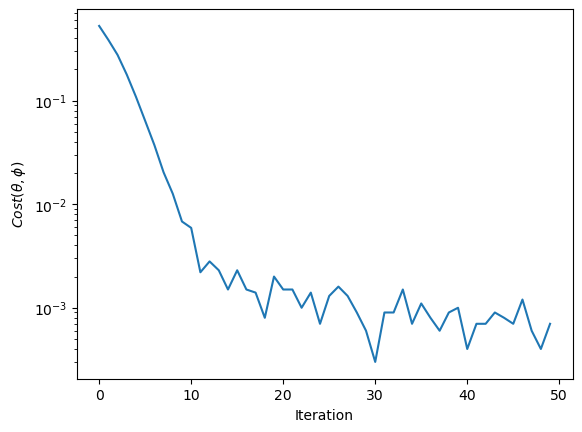

In [8]:
settings = qnp.random.rand(2)
default_cost_vals = []

num_steps = 50
for i in range(num_steps):
    settings, cost = opt.step_and_cost(default_cost, settings)
    default_cost_vals += [cost]

plt.semilogy(range(num_steps), default_cost_vals)
plt.ylabel(r"$Cost(\theta,\phi)$")
plt.xlabel("Iteration")

plt.show()

### Optimizing Using the Custom Kinesis device.

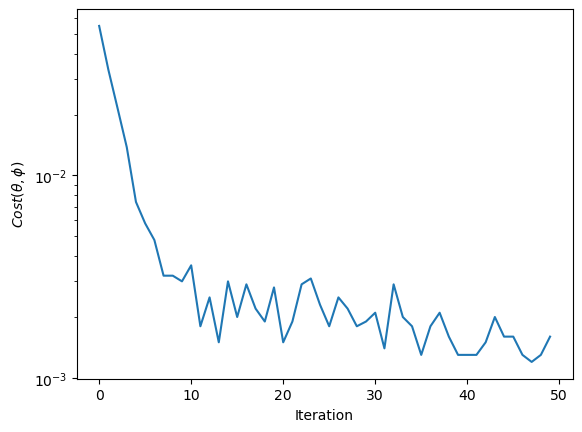

In [9]:
settings = qnp.random.rand(2)
kinesis_cost_vals = []

num_steps = 50
for i in range(num_steps):
    settings, cost = opt.step_and_cost(kinesis_cost, settings)
    kinesis_cost_vals += [cost]

plt.semilogy(range(num_steps), kinesis_cost_vals)
plt.ylabel(r"$Cost(\theta,\phi)$")
plt.xlabel("Iteration")

plt.show()